In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
import joblib
from tensorflow.keras.models import load_model
from itertools import cycle

# Use one of these style settings:
sns.set_style("darkgrid")  # or
# sns.set_theme()

In [3]:
X_test = np.load('X_test.npy')
Y_test = np.load('Y_test.npy')
y_pred = np.load('y_pred.npy')
y_original = np.load('y_original.npy')
history = joblib.load('training_history.joblib')
model = load_model('stress_level_model.h5')

# Convert predictions to class labels
y_test_classes = np.argmax(Y_test, axis=1)
y_pred_classes = np.argmax(y_pred, axis=1)

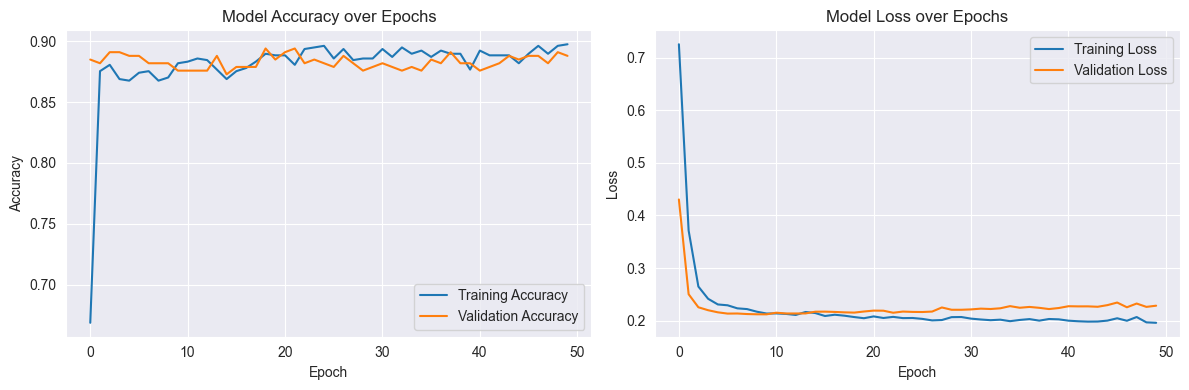

In [4]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history['accuracy'], label='Training Accuracy')
plt.plot(history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history['loss'], label='Training Loss')
plt.plot(history['val_loss'], label='Validation Loss')
plt.title('Model Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

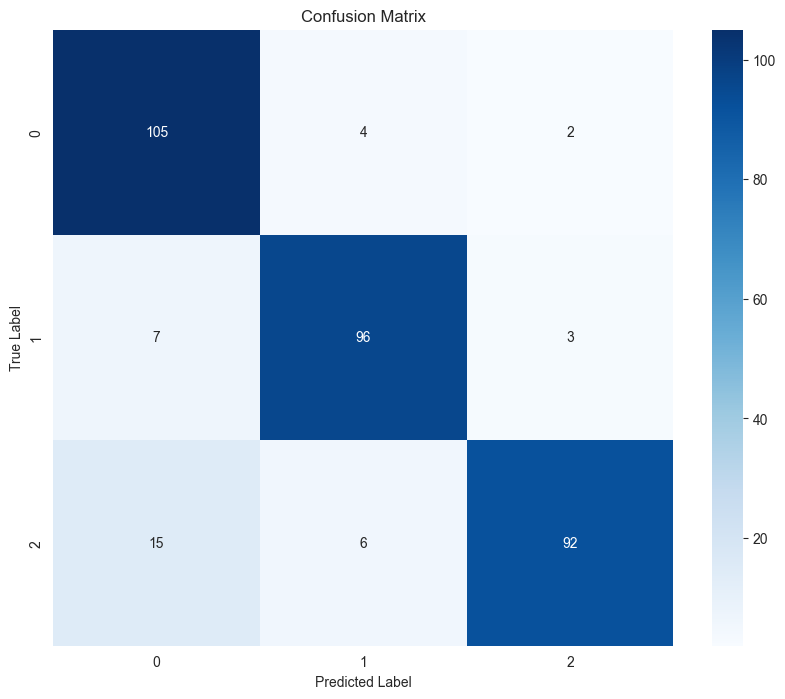


Classification Report:
               precision    recall  f1-score   support

   Low Stress       0.83      0.95      0.88       111
Medium Stress       0.91      0.91      0.91       106
  High Stress       0.95      0.81      0.88       113

     accuracy                           0.89       330
    macro avg       0.89      0.89      0.89       330
 weighted avg       0.89      0.89      0.89       330



In [5]:
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_test_classes, y_pred_classes)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

print("\nClassification Report:")
print(classification_report(y_test_classes, y_pred_classes, 
                          target_names=['Low Stress', 'Medium Stress', 'High Stress']))

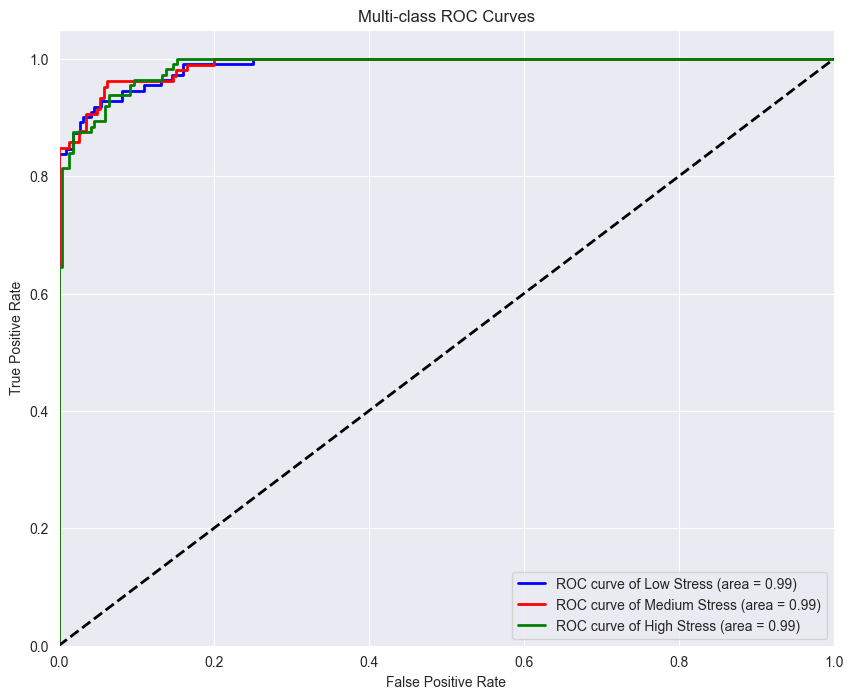

In [6]:
n_classes = 3
fpr = dict()
tpr = dict()
roc_auc = dict()

# Compute ROC curve and ROC area for each class
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(Y_test[:, i], y_pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot ROC curves
plt.figure(figsize=(10, 8))
colors = cycle(['blue', 'red', 'green'])
classes = ['Low Stress', 'Medium Stress', 'High Stress']

for i, color, cls in zip(range(n_classes), colors, classes):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'ROC curve of {cls} (area = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multi-class ROC Curves')
plt.legend(loc="lower right")
plt.show()

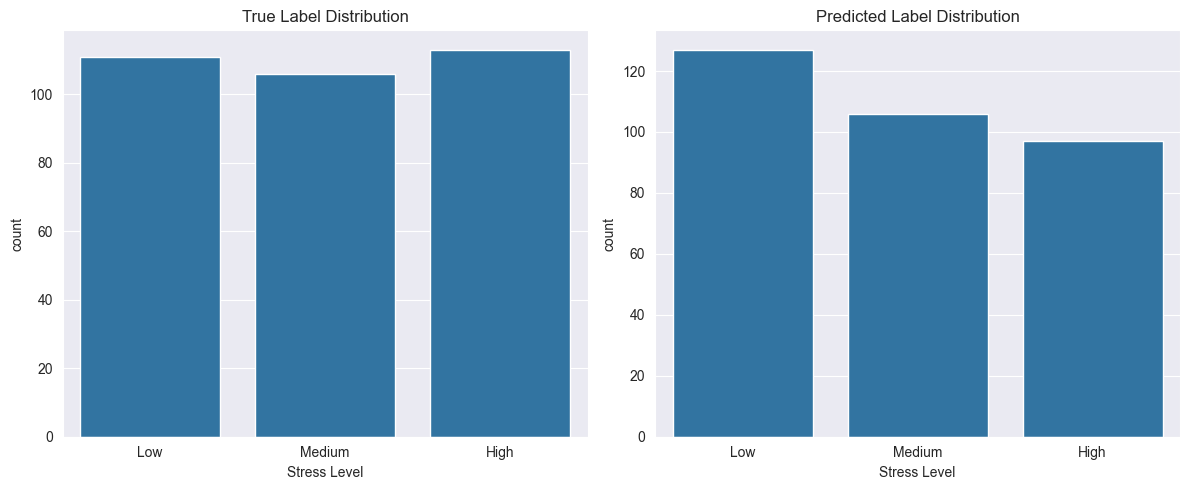

In [7]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.countplot(x=y_test_classes)
plt.title('True Label Distribution')
plt.xlabel('Stress Level')
plt.xticks([0, 1, 2], ['Low', 'Medium', 'High'])

plt.subplot(1, 2, 2)
sns.countplot(x=y_pred_classes)
plt.title('Predicted Label Distribution')
plt.xlabel('Stress Level')
plt.xticks([0, 1, 2], ['Low', 'Medium', 'High'])

plt.tight_layout()
plt.show()

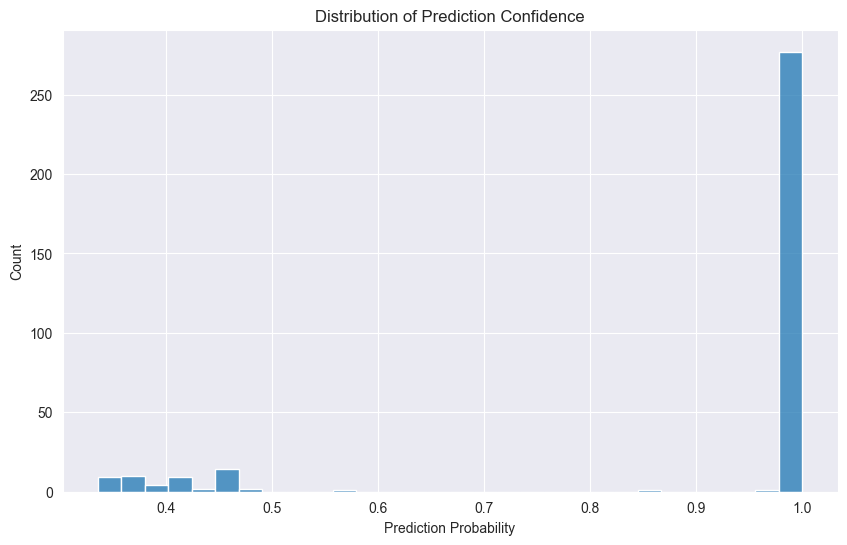

Average prediction confidence: 0.908
Median prediction confidence: 1.000
Minimum prediction confidence: 0.336
Maximum prediction confidence: 1.000


In [8]:
plt.figure(figsize=(10, 6))
max_probabilities = np.max(y_pred, axis=1)
sns.histplot(max_probabilities, bins=30)
plt.title('Distribution of Prediction Confidence')
plt.xlabel('Prediction Probability')
plt.ylabel('Count')
plt.show()

# Print some statistics about prediction confidence
print(f"Average prediction confidence: {np.mean(max_probabilities):.3f}")
print(f"Median prediction confidence: {np.median(max_probabilities):.3f}")
print(f"Minimum prediction confidence: {np.min(max_probabilities):.3f}")
print(f"Maximum prediction confidence: {np.max(max_probabilities):.3f}")